In [1]:
import pandas as pd
import sqlite3

# 1. 创建专门用于风控项目的数据库
conn = sqlite3.connect('home_credit.db')
print("⏳ 数据库连接已建立，开始进行大文件分块导入（大概需要 1-2 分钟，请耐心等待）...")

# 2. 导入核心主表 (约 30 万行)
print("▶️ 正在导入 application_train.csv ...")
df_train = pd.read_csv('application_train.csv')
# 使用 chunksize 分批写入，防止内存撑爆
df_train.to_sql('application_train', conn, if_exists='replace', index=False, chunksize=10000)

# 3. 导入外部征信表 (约 170 万行)
print("▶️ 正在导入 bureau.csv ...")
df_bureau = pd.read_csv('bureau.csv')
df_bureau.to_sql('bureau', conn, if_exists='replace', index=False, chunksize=10000)

# 4. 导入内部历史申请表 (约 167 万行)
print("▶️ 正在导入 previous_application.csv ...")
df_prev = pd.read_csv('previous_application.csv')
df_prev.to_sql('previous_application', conn, if_exists='replace', index=False, chunksize=10000)

print("全部核心数据表成功导入本地 SQLite 数据库！")

⏳ 数据库连接已建立，开始进行大文件分块导入（大概需要 1-2 分钟，请耐心等待）...
▶️ 正在导入 application_train.csv ...
▶️ 正在导入 bureau.csv ...
▶️ 正在导入 previous_application.csv ...
全部核心数据表成功导入本地 SQLite 数据库！


In [2]:
import pandas as pd
import sqlite3

conn = sqlite3.connect('home_credit.db')

# 阶段一：跨表特征工程 (SQL 核心逻辑)
feature_sql = """
SELECT 
    -- 1. 主表核心字段
    a.SK_ID_CURR,
    a.TARGET,
    a.CODE_GENDER,
    a.FLAG_OWN_CAR,
    a.FLAG_OWN_REALTY,
    a.AMT_INCOME_TOTAL AS income,
    a.AMT_CREDIT AS credit_amount,
    a.DAYS_BIRTH,
    a.DAYS_EMPLOYED,
    
    -- 2. 外部征信表 (bureau) 衍生特征：历史负债与逾期情况
    IFNULL(b.bureau_loan_count, 0) AS bureau_loan_count,
    IFNULL(b.total_debt, 0) AS total_debt,
    IFNULL(b.max_overdue_days, 0) AS max_overdue_days,
    
    -- 3. 内部历史申请表 (previous_application) 衍生特征：曾经被拒贷的次数
    IFNULL(p.prev_refused_count, 0) AS prev_refused_count
    
FROM application_train a

-- 【关键逻辑 1】聚合 bureau 表，提取每个人的外部贷款总数、总负债、最大逾期天数
LEFT JOIN (
    SELECT 
        SK_ID_CURR,
        COUNT(SK_ID_BUREAU) AS bureau_loan_count,
        SUM(AMT_CREDIT_SUM) AS total_debt,
        MAX(CREDIT_DAY_OVERDUE) AS max_overdue_days
    FROM bureau
    GROUP BY SK_ID_CURR
) b ON a.SK_ID_CURR = b.SK_ID_CURR

-- 【关键逻辑 2】聚合 previous_application 表，用 CASE WHEN 统计历史被拒贷次数
LEFT JOIN (
    SELECT 
        SK_ID_CURR,
        SUM(CASE WHEN NAME_CONTRACT_STATUS = 'Refused' THEN 1 ELSE 0 END) AS prev_refused_count
    FROM previous_application
    GROUP BY SK_ID_CURR
) p ON a.SK_ID_CURR = p.SK_ID_CURR
"""

print("⏳ 正在执行复杂跨表特征提取，这需要几十秒钟，让子弹飞一会儿...")
# 读取 SQL 执行结果到 Pandas DataFrame
df_features = pd.read_sql(feature_sql, conn)
conn.close()

print(f"✅ 特征宽表提取完成！数据维度: {df_features.shape}")
display(df_features.head())

⏳ 正在执行复杂跨表特征提取，这需要几十秒钟，让子弹飞一会儿...
✅ 特征宽表提取完成！数据维度: (307511, 13)


,SK_ID_CURR,TARGET,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,income,credit_amount,DAYS_BIRTH,DAYS_EMPLOYED,bureau_loan_count,total_debt,max_overdue_days,prev_refused_count
0,100002,1,M,N,Y,202500.0,406597.5,-9461,-637,8,865055.565,0,0
1,100003,0,F,N,N,270000.0,1293502.5,-16765,-1188,4,1017400.500,0,0
2,100004,0,M,Y,Y,67500.0,135000.0,-19046,-225,2,189037.800,0,0
3,100006,0,F,N,Y,135000.0,312682.5,-19005,-3039,0,0.000,0,1
4,100007,0,M,N,Y,121500.0,513000.0,-19932,-3038,1,146250.000,0,0


In [3]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, classification_report
import numpy as np

# --- 阶段二：工业级数据预处理 ---

# 1. 业务逻辑转换：把反人类的“出生天数(负数)”换算成“年龄(正数)”
df_features['age'] = df_features['DAYS_BIRTH'] / -365
df_features['years_employed'] = df_features['DAYS_EMPLOYED'] / -365

# 银行数据常识：DAYS_EMPLOYED 里有个神奇的异常值 365243 (算下来是 -1000 年)，代表“未就业/退休”
# 我们把它替换为真正的缺失值 NaN，让 LightGBM 自己去消化它
df_features['years_employed'] = df_features['years_employed'].replace(-1000.6657534246575, np.nan) 

# 2. 类别特征转化：告诉 LightGBM 哪些是类别变量
cat_cols = ['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY']
for col in cat_cols:
    df_features[col] = df_features[col].astype('category')

# 删除原始的不合理列和 ID 列 (ID 绝对不能参与训练)
X = df_features.drop(columns=['SK_ID_CURR', 'TARGET', 'DAYS_BIRTH', 'DAYS_EMPLOYED'])
y = df_features['TARGET']


# --- 阶段三：LightGBM 模型训练 ---

# 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("🚀 正在训练 LightGBM 风控模型 (包含 30万 数据量)...")
# 初始化模型：这里再次利用 class_weight='balanced' 解决风控中 违约人数极少 的样本不平衡问题！
lgb_model = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=6,
    class_weight='balanced',  # 🌟 强迫模型重点关注违约的少数群体
    random_state=42,
    n_jobs=-1                 # 调用你电脑的所有 CPU 核心满载运行
)

# 拟合模型
lgb_model.fit(X_train, y_train)

# 预测与评估
y_pred_prob = lgb_model.predict_proba(X_test)[:, 1]
y_pred = lgb_model.predict(X_test)

print("\n--- 📊 LightGBM 风控模型评估报告 ---")
print(classification_report(y_test, y_pred))
print(f"🌟 ROC-AUC 得分: {roc_auc_score(y_test, y_pred_prob):.4f}")

🚀 正在训练 LightGBM 风控模型 (包含 30万 数据量)...
[LightGBM] [Info] Number of positive: 19876, number of negative: 226132
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005260 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1570
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 11
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000

--- 📊 LightGBM 风控模型评估报告 ---
              precision    recall  f1-score   support

           0       0.95      0.62      0.75     56554
           1       0.12      0.62      0.21      4949

    accuracy                           0.62     61503
   macro avg       0.54      0.62      0.48     61503
weighted avg       0.88      0.62      0.70     61503

🌟 ROC-AUC 得分: 0.6613


## 结果分析
### 召回率 
测试集里真实违约的用户找到了62%（加权处理）
### 精确率
预测会违约的人里面只有12%是真的违约了，误杀太多
### AUC
区分能力一般
## LightGBM算法原理
开始预测>计算残差>拟合>重新预测>计算新残差>重复
最终输出为所有树输出的加权和
其实是一种随机森林
### 技术创新
#### 单边梯度采样
传统的GBDT要全部计算梯度，不适合大量数据，GOSS保留大梯度样本，其需要学习，随机采样小梯度样本，最终给小梯度样本加权补偿
#### 互斥特征捆绑
高维数据中很多特征都是稀疏的，某些特征几乎不会同时非零，就可以把它捆绑成一个特征，减少维度，加快速度
## 什么是XGBoost
boosting方法拟合上一棵树的残差，最终加权所有的结果
在最小化损失函数的同时加入正则化项来惩罚树的复杂度，以防止过拟合，泛化能力更强，比传统方法更快更准
## GBDT gradient boosting decision tree
训练多可决策树，每棵树都去拟合前一棵树留下的残差，预测结果为加权和，用决策树去拟合损失函数的负梯度方向

🔍 正在计算 SHAP 值分析模型决策逻辑（取前 2000 个样本以加快计算速度）...


/opt/anaconda3/envs/ml_sql/lib/python3.10/site-packages/shap/explainers/_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


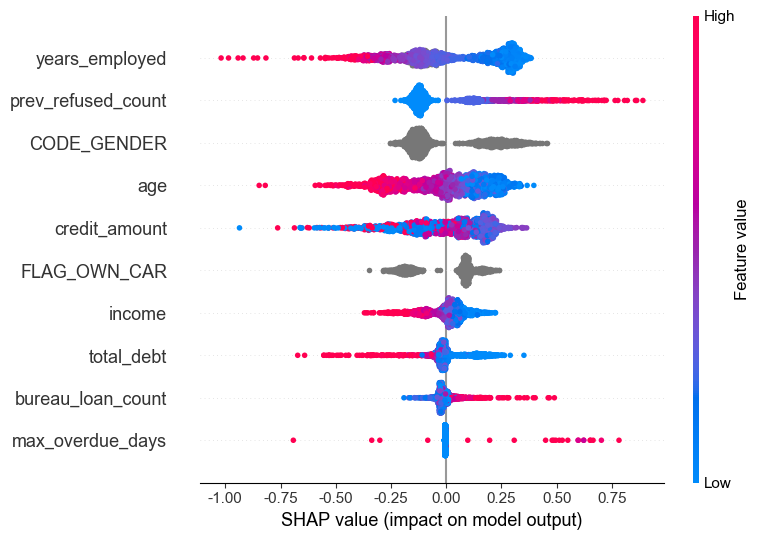

In [4]:
import shap
import matplotlib.pyplot as plt

print("🔍 正在计算 SHAP 值分析模型决策逻辑（取前 2000 个样本以加快计算速度）...")

# 1. 把 LightGBM 喂给 SHAP 的树解释器
explainer = shap.TreeExplainer(lgb_model)

# 2. 选取一部分测试集数据计算 SHAP 值
X_test_sample = X_test.iloc[:2000]
shap_values = explainer.shap_values(X_test_sample)

# 兼容不同的 LightGBM 版本返回的 shap_values 格式
# 如果返回的是 list，取索引 1 (代表违约概率的影响)
if isinstance(shap_values, list):
    shap_vals_to_plot = shap_values[1]
else:
    shap_vals_to_plot = shap_values

# 3. 绘制 SHAP 摘要图 (Summary Plot)
# 解决中文字体显示问题 (如果是 Mac，使用 Arial Unicode MS)
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_to_plot, X_test_sample, max_display=10)

## SHAP是干嘛的
对于集成树模型我们认为是黑盒的，SHAP是来拆解的，SHAP value图表明模型是通过哪些客户特征来判断是不是老赖
### 如何看图
Y轴即特征重要性，X轴是对违约概率的影响，正值是提高了违约概率，负值降低了概率，红色代表高值，蓝色代表低值


In [5]:
import pandas as pd
import sqlite3
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import numpy as np

conn = sqlite3.connect('home_credit.db')

# --- 阶段一：进阶 SQL 特征工程 (V2.0) ---
print("⏳ 正在执行 V2.0 高阶跨表特征提取，请稍候...")
feature_sql_v2 = """
SELECT 
    a.SK_ID_CURR, a.TARGET, a.CODE_GENDER, a.FLAG_OWN_CAR, a.FLAG_OWN_REALTY,
    a.AMT_INCOME_TOTAL AS income, a.AMT_CREDIT AS credit_amount, a.DAYS_BIRTH, a.DAYS_EMPLOYED,
    
    -- 外部征信表进阶特征
    IFNULL(b.bureau_loan_count, 0) AS bureau_loan_count,
    IFNULL(b.active_loan_count, 0) AS active_loan_count,
    IFNULL(b.total_debt, 0) AS total_debt,
    IFNULL(b.max_overdue_days, 0) AS max_overdue_days,
    -- 核心风控特征：信贷使用率 (分母加 0.001 防止除以 0 报错)
    IFNULL(b.total_debt, 0) / (IFNULL(b.total_credit, 0) + 0.001) AS debt_to_credit_ratio,

    -- 内部历史表进阶特征
    IFNULL(p.prev_refused_count, 0) AS prev_refused_count,
    IFNULL(p.prev_approved_count, 0) AS prev_approved_count,
    IFNULL(p.mean_prev_annuity, 0) AS mean_prev_annuity

FROM application_train a

-- 聚合外部征信表 (bureau)
LEFT JOIN (
    SELECT 
        SK_ID_CURR,
        COUNT(SK_ID_BUREAU) AS bureau_loan_count,
        SUM(CASE WHEN CREDIT_ACTIVE = 'Active' THEN 1 ELSE 0 END) AS active_loan_count,
        SUM(AMT_CREDIT_SUM) AS total_credit,
        SUM(AMT_CREDIT_SUM_DEBT) AS total_debt,
        MAX(CREDIT_DAY_OVERDUE) AS max_overdue_days
    FROM bureau
    GROUP BY SK_ID_CURR
) b ON a.SK_ID_CURR = b.SK_ID_CURR

-- 聚合内部历史表 (previous_application)
LEFT JOIN (
    SELECT 
        SK_ID_CURR,
        SUM(CASE WHEN NAME_CONTRACT_STATUS = 'Refused' THEN 1 ELSE 0 END) AS prev_refused_count,
        SUM(CASE WHEN NAME_CONTRACT_STATUS = 'Approved' THEN 1 ELSE 0 END) AS prev_approved_count,
        AVG(AMT_ANNUITY) AS mean_prev_annuity
    FROM previous_application
    GROUP BY SK_ID_CURR
) p ON a.SK_ID_CURR = p.SK_ID_CURR
"""

df_features_v2 = pd.read_sql(feature_sql_v2, conn)
conn.close()

# --- 阶段二：工业级数据预处理 ---
# 年龄与工作年限处理
df_features_v2['age'] = df_features_v2['DAYS_BIRTH'] / -365
df_features_v2['years_employed'] = df_features_v2['DAYS_EMPLOYED'] / -365
df_features_v2['years_employed'] = df_features_v2['years_employed'].replace(-1000.6657534246575, np.nan) 

# 类别特征转化
cat_cols = ['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY']
for col in cat_cols:
    df_features_v2[col] = df_features_v2[col].astype('category')

# 切分特征与标签
X_v2 = df_features_v2.drop(columns=['SK_ID_CURR', 'TARGET', 'DAYS_BIRTH', 'DAYS_EMPLOYED'])
y_v2 = df_features_v2['TARGET']

# --- 阶段三：LightGBM 模型重训 ---
X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(X_v2, y_v2, test_size=0.2, random_state=42)

print("🚀 正在训练 V2.0 进阶模型...")
lgb_model_v2 = lgb.LGBMClassifier(
    n_estimators=100, learning_rate=0.05, max_depth=6,
    class_weight='balanced', random_state=42, n_jobs=-1
)
lgb_model_v2.fit(X_train_v2, y_train_v2)

# 评估 V2.0 模型
y_pred_prob_v2 = lgb_model_v2.predict_proba(X_test_v2)[:, 1]
new_auc = roc_auc_score(y_test_v2, y_pred_prob_v2)

print(f"\n🎉 训练完成！")
print(f"📈 旧版基线 AUC 得分: 0.6613")
print(f"🌟 V2.0 进阶 AUC 得分: {new_auc:.4f}")

⏳ 正在执行 V2.0 高阶跨表特征提取，请稍候...
🚀 正在训练 V2.0 进阶模型...
[LightGBM] [Info] Number of positive: 19876, number of negative: 226132
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003575 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2124
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000

🎉 训练完成！
📈 旧版基线 AUC 得分: 0.6613
🌟 V2.0 进阶 AUC 得分: 0.6888


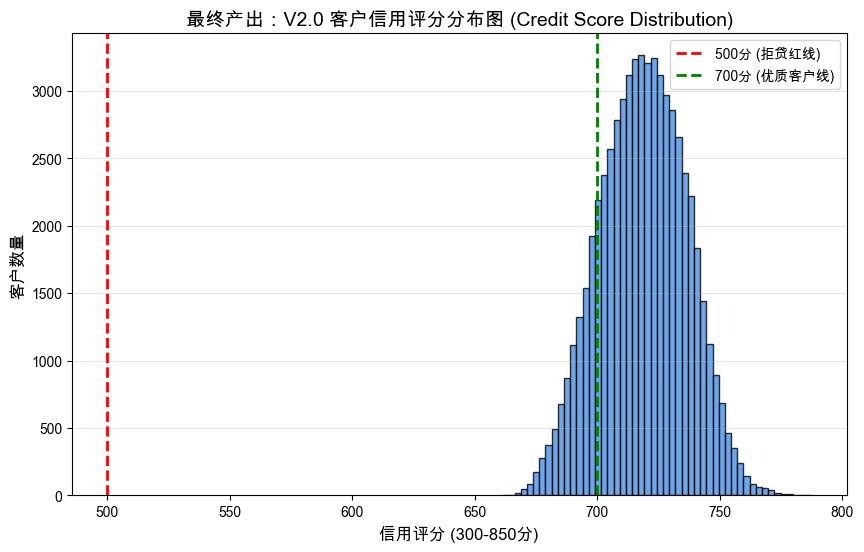

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 提取 V2.0 模型预测的违约概率
p = y_pred_prob_v2

# 2. 核心数学映射：将概率转化为赔率 (Odds)
# 赔率 = 违约概率 / 不违约概率 (为了防止除以0，做一点边界截断)
p = np.clip(p, 1e-5, 1 - 1e-5)
odds = p / (1 - p)

# 3. 评分卡公式 (标准的对数几率转换)
# 设定行业标准：假设 Odds 为 1:50 的人，得 600 分 (Base Score)
# 每当 Odds 翻一倍 (PDO = 20)，分数减少 20 分
factor = 20 / np.log(2)
offset = 600 - factor * np.log(1/50)

# 计算初始信用评分 (违约概率越高，分数越低)
credit_scores = offset - factor * np.log(odds)

# 模拟真实的芝麻信用/FICO体系，把分数强制限制在 300 到 850 分之间
credit_scores = np.clip(credit_scores, 300, 850)

# 4. 可视化我们自己的“信用分”分布
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS'] # Mac 中文字体支持
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(10, 6))
plt.hist(credit_scores, bins=50, color='#4A90E2', edgecolor='black', alpha=0.8)
plt.title('最终产出：V2.0 客户信用评分分布图 (Credit Score Distribution)', fontsize=14)
plt.xlabel('信用评分 (300-850分)', fontsize=12)
plt.ylabel('客户数量', fontsize=12)

# 画几条业务红线
plt.axvline(500, color='red', linestyle='dashed', linewidth=2, label='500分 (拒贷红线)')
plt.axvline(700, color='green', linestyle='dashed', linewidth=2, label='700分 (优质客户线)')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()